# SymPhase tutorial 7 — incommensurate spirals without supercells

A single-Q planar spiral $\mathbf S_j(\mathbf R)=R_{\hat{\mathbf n}}(\mathbf Q\cdot\mathbf R)\,\mathbf S_j(\mathbf 0)$ is **not periodic** in the
crystal cell, and an incommensurate $\mathbf Q$ fits no finite supercell. If the Hamiltonian is invariant under rotations about
$\hat{\mathbf n}$ (Heisenberg exchange, DM vectors $\parallel\hat{\mathbf n}$, anisotropy along $\hat{\mathbf n}$), the order becomes periodic in the
**rotating frame**: every bond matrix is replaced by
$$J_{ij}(\mathbf R)\;\longrightarrow\;J_{ij}(\mathbf R)\,R_{\hat{\mathbf n}}(2\pi\,\mathbf q\cdot\mathbf R),$$
and the general non-collinear LSWT runs on the original (small) magnetic cell. SymPhase

1. finds the optimal $\mathbf q$ by minimising the classical spiral energy $E(\mathbf q,\{\psi_i\})$ (grid + Nelder–Mead), or uses a given $\mathbf q$,
2. checks that the Hamiltonian is rotation-invariant about $\hat{\mathbf n}$ (otherwise it refuses: a supercell is needed),
3. computes the magnons in the rotating frame (neutron intensity appears at $\mathbf k$ and $\mathbf k\pm\mathbf q$),
4. with `--relax` (fixed cell) it warns when an incommensurate spiral would be lower in energy.

Validated against the analytic $J_1$–$J_2$ chain, the DMI helix and an explicit 6-site supercell (tests).

In [1]:
# run this first (works from the repository's notebooks/ folder)
import os, sys
sys.path.insert(0, os.path.abspath(".."))      # use the local package if not pip-installed
EX = os.path.abspath("../examples")
%matplotlib inline

## 1. Frustrated $J_1$–$J_2$ chain (one atom per cell)

Classically $\cos(2\pi q)=-J_1/(4J_2)$ when $J_2>|J_1|/4$; for $J_1=-1$, $J_2=0.5$ meV: $q=1/6$.

In [2]:
import numpy as np, spglib, math
import matplotlib.pyplot as plt
from symphase.magnons import analyse, read_exchange_file, plot_bands
a = 3.0
lat, fr = np.diag([a, 12, 12]), np.zeros((1, 3))
ds = spglib.get_symmetry_dataset((lat, fr, [0]))
m0 = np.array([[0, 0, 2.0]])
r = analyse(lat, fr, [0], ["Fe"], m0, ds.rotations, ds.translations, J=[-1.0, 0.5], spin=1.0, rmax=6.1,
            spiral="auto", spiral_axis=[0, 0, 1], n_per=60, nmap=3)
sp = r["spiral"]
print("q =", np.round(sp["q_rlu"], 6), "r.l.u.;  period", round(sp["period_A"], 3), "Å;  E =", sp["E_spiral"],
      "meV/site (ferromagnet:", sp["E_start"], ")")

q = [-0.166667  0.        0.      ] r.l.u.;  period 18.0 Å;  E = -0.7500000000000001 meV/site (ferromagnet: -0.5 )


max |error| = 3.5355345382723096e-05 meV


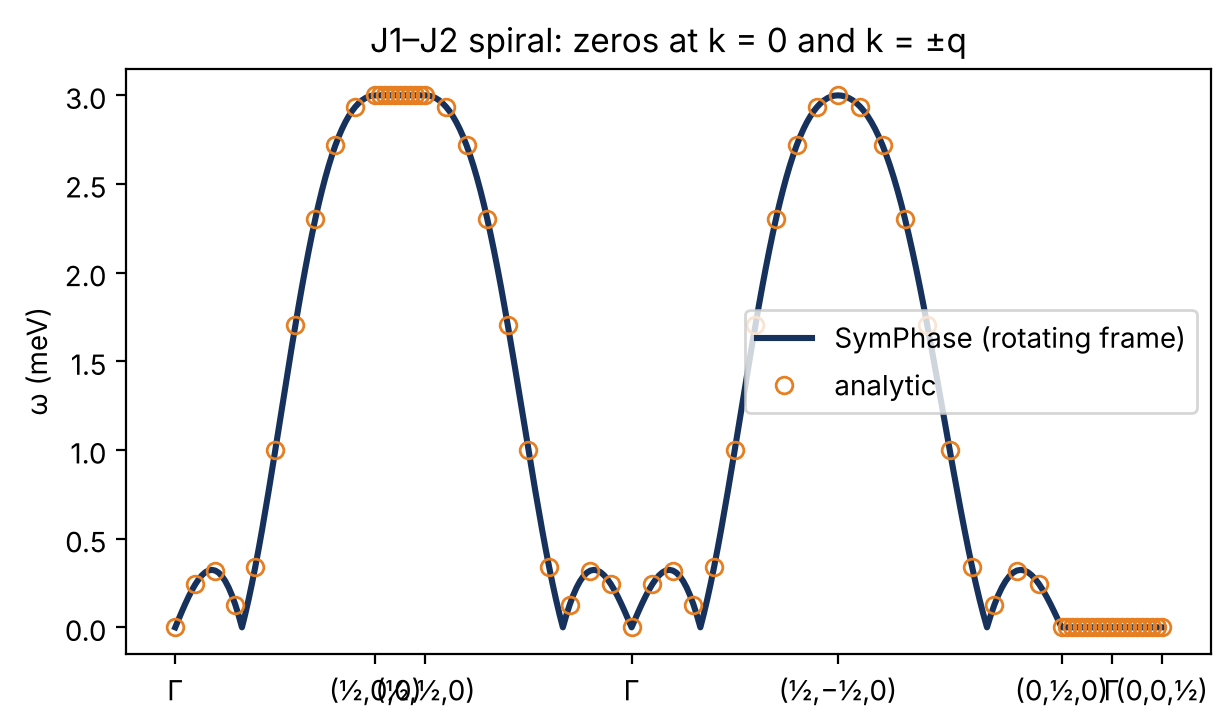

In [3]:
Jk = lambda k: -2 * np.cos(k * a) + np.cos(2 * k * a)
Q = 2 * np.pi * abs(sp["q_rlu"][0]) / a
ana = [np.sqrt(max((Jk(k) - Jk(Q)) * ((Jk(k + Q) + Jk(k - Q)) / 2 - Jk(Q)), 0)) for k in r["q"][:, 0]]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(r["x"], r["omega"][:, 0], color="#16325c", lw=2.2, label="SymPhase (rotating frame)")
ax.plot(r["x"][::6], ana[::6], "o", color="#e67e22", mfc="none", label="analytic")
ax.set_xticks([t for t, _ in r["ticks"]]); ax.set_xticklabels([l for _, l in r["ticks"]]); ax.set_ylabel("ω (meV)")
ax.legend(); ax.set_title("J1–J2 spiral: zeros at k = 0 and k = ±q")
print("max |error| =", np.max(np.abs(r["omega"][:, 0] - ana)), "meV")

## 2. Phase diagram: when is the spiral stable?

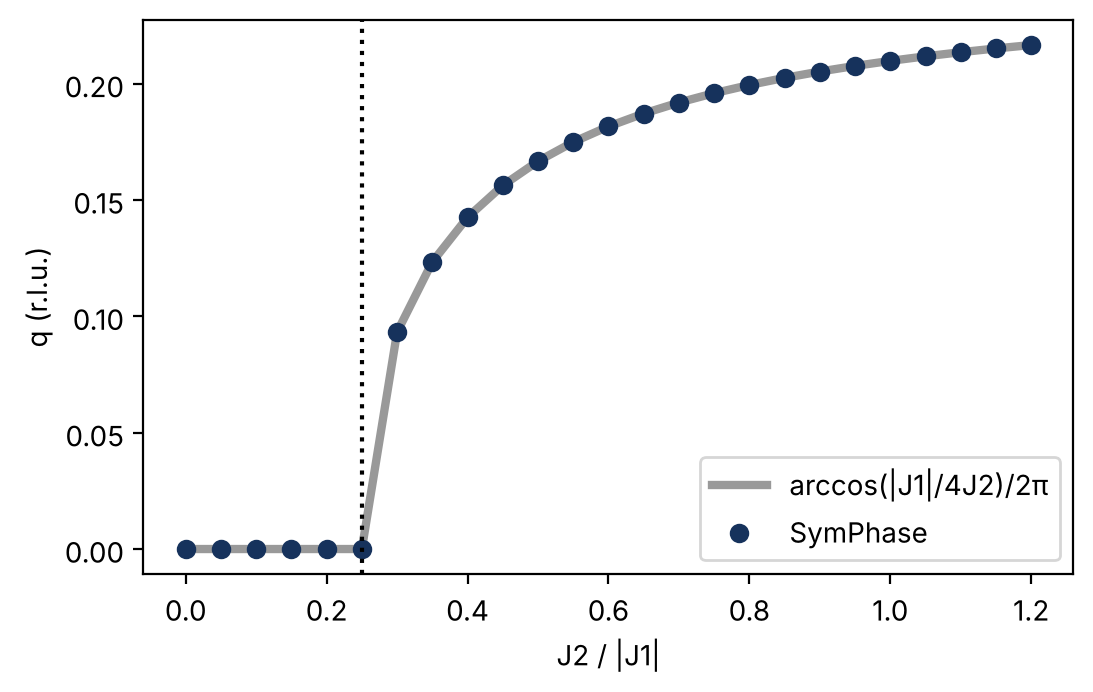

In [4]:
J2s = np.linspace(0.0, 1.2, 25)
qs = [abs(analyse(lat, fr, [0], ["Fe"], m0, ds.rotations, ds.translations, J=[-1.0, j2], spin=1.0, rmax=6.1,
                  spiral="auto", spiral_axis=[0, 0, 1], n_per=4, nmap=3)["spiral"]["q_rlu"][0]) for j2 in J2s]
exact = [math.acos(min(1, 1 / (4 * j2))) / (2 * np.pi) if j2 > 0.25 else 0 for j2 in J2s]
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(J2s, exact, color="0.6", lw=3, label="arccos(|J1|/4J2)/2π")
ax.plot(J2s, qs, "o", color="#16325c", label="SymPhase")
ax.axvline(0.25, ls=":", color="k"); ax.set_xlabel("J2 / |J1|"); ax.set_ylabel("q (r.l.u.)"); ax.legend()

## 3. Helix from a uniform Dzyaloshinskii–Moriya interaction

Ferromagnetic chain with $\mathbf D\parallel\hat{\mathbf x}$ along the chain: a **Bloch helix** in the plane ⊥ x with
$\tan(2\pi q)=D/|J|$ — here $q=0.0314$ r.l.u., a period of 95.5 Å (31.8 lattice constants): impossible to fit in a small supercell,
trivial in the rotating frame. The sign of $q$ (handedness) is fixed by the sign of $D$.

In [5]:
d = f"{EX}/vasp/Helix_DMI_chain"
print(open(f"{d}/J_DMI.dat").read())
r = analyse(lat, fr, [0], ["Fe"], m0, ds.rotations, ds.translations, exchange=read_exchange_file(f"{d}/J_DMI.dat"),
            spin=1.0, rmax=3.1, spiral="auto", n_per=60, nmap=3)
sp = r["spiral"]
print("q =", round(sp["q_rlu"][0], 6), " expected ±", round(math.atan(0.2) / (2 * np.pi), 6), "; axis", sp["axis"],
      "; period", round(sp["period_A"], 2), "Å =", round(sp["period_A"] / a, 2), "a")

# i j n1 n2 n3   J     Dx   Dy  Dz   (meV)   uniform DM vector along the chain
1 1 1 0 0   -1.0  0.2  0.0  0.0



q = -0.031416  expected ± 0.031416 ; axis [1.0, 0.0, 0.0] ; period 95.49 Å = 31.83 a


## 4. The fixed-cell trap, now detected

With `relax=True` in the 1-atom cell the best commensurate state is the ferromagnet; SymPhase reports that a spiral is lower:

In [6]:
r = analyse(lat, fr, [0], ["Fe"], m0, ds.rotations, ds.translations, J=[-1.0, 0.5], spin=1.0, rmax=6.1,
            relax=True, n_per=4, nmap=3)
print("relaxed (fixed cell):", r["E_classical"], "meV;  spiral check:", r["spiral_check"])

relaxed (fixed cell): -0.5 meV;  spiral check: {'q_rlu': [-0.16666666746139525, 0.0, 0.0], 'E_spiral': -0.75, 'axis': [0.0, 0.0, 1.0], 'lower': True}


## 5. Command line

```bash
cd examples/vasp/Spiral_J1J2_chain && symphase magnons --J -1.0 0.5 --rmax 6.1 --spin 1 --spiral auto
cd examples/vasp/Helix_DMI_chain   && symphase magnons --exchange J_DMI.dat --rmax 3.1 --spin 1 --spiral auto
symphase magnons ... --spiral 0.25 0 0 --spiral-axis 0 0 1      # fixed q (r.l.u.) and rotation axis
symphase magnons ... --spiral auto --qdims 0 1                   # search q in the a*-b* plane only
```
Limits: single-Q planar spirals; anisotropy or DM vectors not parallel to $\hat{\mathbf n}$ break the rotating-frame symmetry —
SymPhase then refuses; those states (multi-Q, conical, distorted spirals) are handled by the supercell workflow of
**12_tutorial_magnetic_supercells.ipynb**. Continue with **11_quiz_noncollinear_spirals.ipynb**.